## First look

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('../data/train-test.csv')
df["date"] = pd.to_datetime(df["date"])

In [3]:
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


Looks like a problem of predicting freight load prices from market history.
- load_id seems to be the main id
- posted_rate seems to be the target.
- pickup, delivery, pickup and delivery coordinates, equipment, weight, date, seem like feature candidates.
- distance may be related to the coordinates, although I am not sure if it is a routing-based calculation or a straight-line distance between the points; if it is the first case it can contain useful information that does not come from the coordinates.
- date can have useful information (prices change depending on specific dates or seasons),
- quote_signal I am not sure what it is
- hypothesis: market_index may not contain really useful information

## Initial exploration

In [4]:
df.describe()   

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.400000,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


In [5]:
df.describe(include="object") 

,load_id,pickup,delivery,equipment
count,48000,48000,48000,48000
unique,48000,64,64,3
top,TR-000001,Oklahoma City,Lexington,Dry Van
freq,1,1242,1197,27202


In [6]:
print(f'load_id. distinct: {df["load_id"].nunique()} duplicated: {df["load_id"].duplicated().sum()}')
print(f'Nulls: \n{df.isna().sum()}')
print(f'interval: {df["date"].min(), df["date"].max()}, {df["date"].max() - df["date"].min()}')

load_id. distinct: 48000 duplicated: 0
Nulls: 
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64
interval: (Timestamp('2025-01-01 00:00:00'), Timestamp('2025-10-31 00:00:00')), 303 days 00:00:00


- load_id has only unique values, it is the main id.
- pickup, delivery and equipment are categorical, with 64, 64 and 3 classes respectively
- weight has 300 missing values, market_index 374
- The period goes from January 1 2025 to October 31 2025, 303 days



## Numeric distributions and correlations

<Axes: >

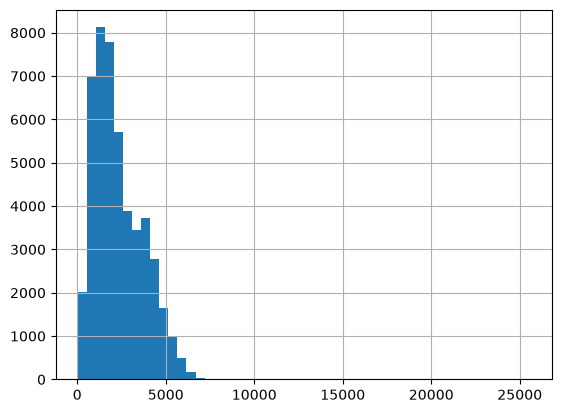

In [7]:
df["posted_rate"].hist(bins=50)          

<Axes: >

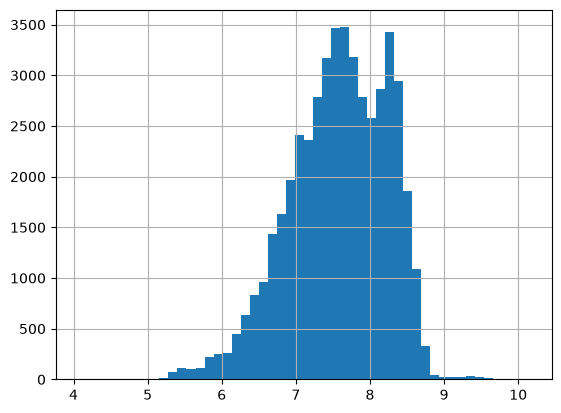

In [8]:
df['posted_rate_log'] = np.log1p(df['posted_rate'])
df["posted_rate_log"].hist(bins=50)    

<Axes: xlabel='weight', ylabel='posted_rate'>

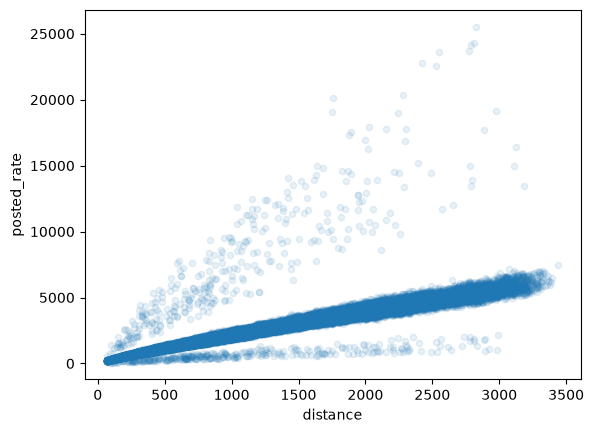

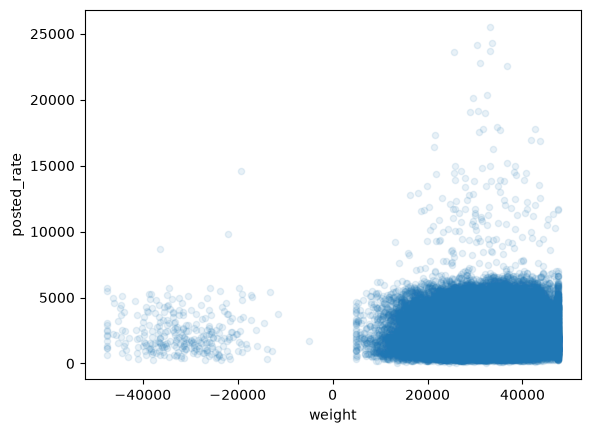

In [9]:
df.plot.scatter(x="distance", y="posted_rate", alpha=0.1)
df.plot.scatter(x="weight", y="posted_rate", alpha=0.1)

In [10]:
df.corr(numeric_only=True)["posted_rate"]  

pickup_lat        -0.090873
pickup_lon        -0.255058
delivery_lat      -0.091970
delivery_lon      -0.257086
distance           0.908519
weight             0.034840
market_index       0.034165
quote_signal      -0.039858
posted_rate        1.000000
posted_rate_log    0.907843
Name: posted_rate, dtype: float64

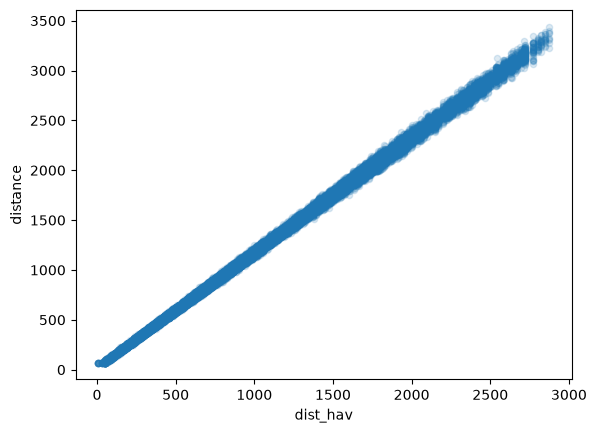

,distance,dist_hav
distance,1.000000,0.999535
dist_hav,0.999535,1.000000


In [11]:
# great-circle distance in miles; compare with given distance column
def haversine_miles(lat1, lon1, lat2, lon2):
    r = 3959.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * r * np.arcsin(np.sqrt(a))

df["dist_hav"] = haversine_miles(
    df["pickup_lat"], df["pickup_lon"],
    df["delivery_lat"], df["delivery_lon"],
)

df.plot.scatter(x="dist_hav", y="distance", alpha=0.15)
plt.show()

df[["distance", "dist_hav"]].corr()

- the target shows a distribution with large outliers, log1p makes the distribution a bit more normal or uniform
- the coordinates explain almost all the information contained in distance according to the calculation
- distance is strongly correlated with the target

Correlations with the target
weight          0.034840
market_index    0.034165
quote_signal   -0.039858

- weight is very weakly correlated with the target, also there appear two big groups of weight scales, the second more concentrated
- market_index and quote_signal correlate with very small magnitudes, positive and negative respectively

Probably distance is the best predictor

## Distribution by categories

<Axes: title={'center': 'posted_rate'}, xlabel='equipment'>

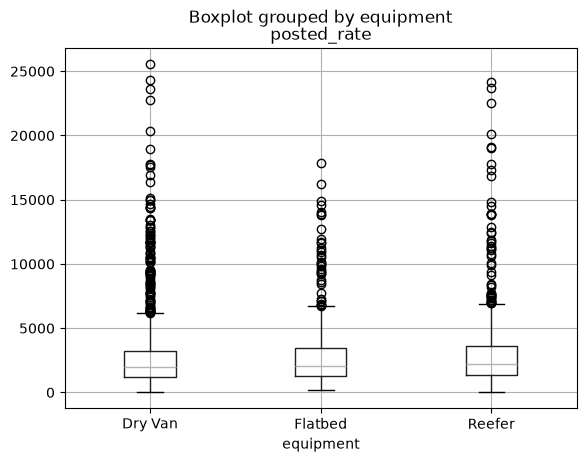

In [12]:
df.boxplot(column="posted_rate", by="equipment")

<Axes: ylabel='pickup'>

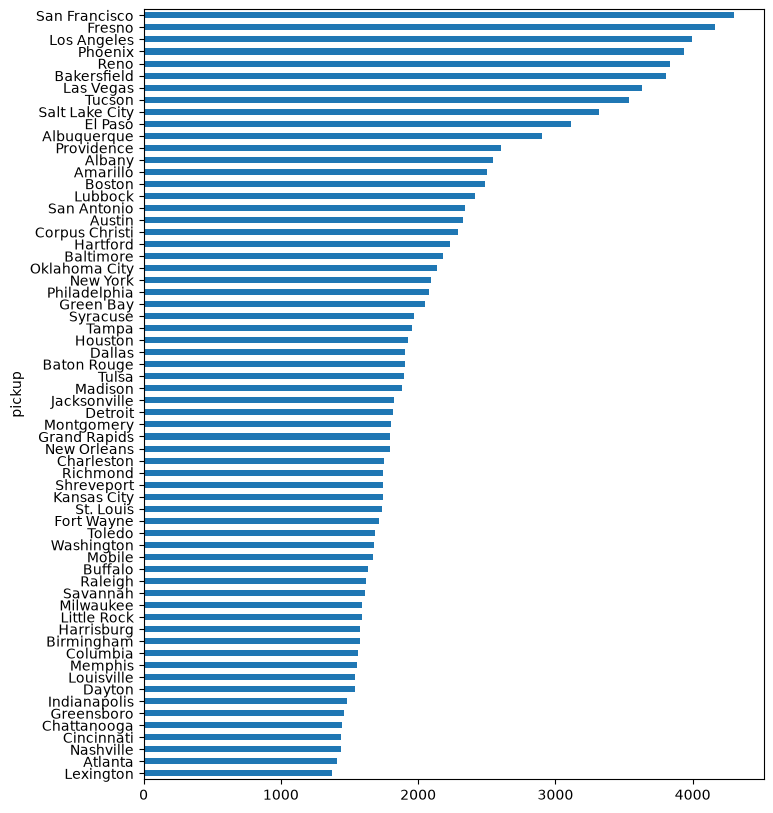

In [13]:
g = df.groupby("pickup")["posted_rate"].median().sort_values()
g.plot(kind="barh", figsize=(8, 10))

<Axes: ylabel='delivery'>

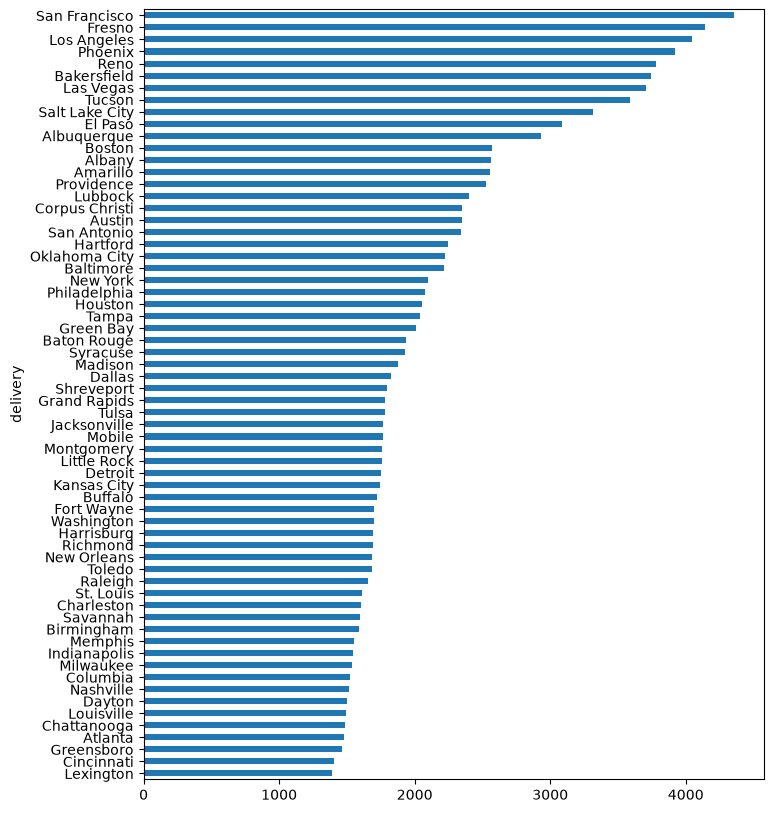

In [14]:
g = df.groupby("delivery")["posted_rate"].median().sort_values()
g.plot(kind="barh", figsize=(8, 10))

In [15]:
# city-level median rates: how similar are origin vs destination rankings?
med_pickup = df.groupby("pickup")["posted_rate"].median()
med_delivery = df.groupby("delivery")["posted_rate"].median()

cmp = pd.concat(
    {"pickup": med_pickup, "delivery": med_delivery},
    axis=1,
)

cmp["pickup"].corr(cmp["delivery"])

np.float64(0.9967463478143646)

- the target with respect to equipment classes seems to be distributed uniformly, but dry van and reefer seem to have more large outliers than flatbed, although it probably does not affect too much
- the rankings of median rate by city are very similar in origin and destination role → there is a signal of "price level by city". Still it is reasonable to treat pickup and delivery as different features, because they describe different ends of the same trip.

## Temporal exploration

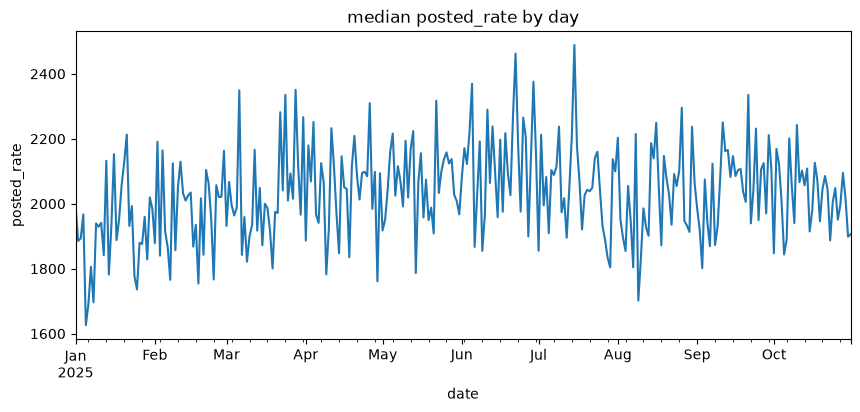

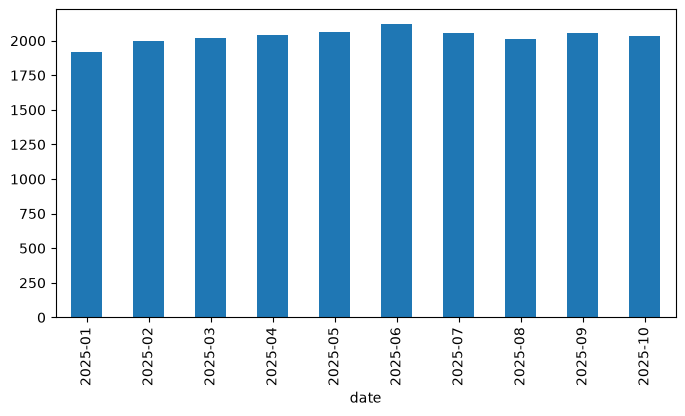

In [16]:
# by day
daily = df.groupby("date")["posted_rate"].median()
daily.plot(figsize=(10, 4), title="median posted_rate by day")
plt.ylabel("posted_rate")
plt.show()

# by month
df.groupby(df["date"].dt.to_period("M"))["posted_rate"].median().plot(kind="bar", figsize=(8, 4))
plt.show()

- there are important variations of the average by day
- the averages do not vary much by month

## Validation check

In [17]:
val = pd.read_csv("../data/validation.csv")
val["date"] = pd.to_datetime(val["date"])

val.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,12000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,2025-12-01 02:30:28.800000256,0.926913,2.051334
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,2025-11-01 00:00:00,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,2025-11-16 00:00:00,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,2025-12-01 00:00:00,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,2025-12-16 00:00:00,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,2025-12-31 00:00:00,1.098950,2.896350
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,NaN,0.074109,0.219804


In [18]:
# count labels in validation that never appear in train-test
cat_cols = ["pickup", "delivery", "equipment"]

for col in cat_cols:
    train_set = set(df[col].dropna().unique())
    val_set = set(val[col].dropna().unique())
    print(col, "unseen in train:", len(val_set - train_set),
          "only in train:", len(train_set - val_set))


pickup unseen in train: 8 only in train: 0
delivery unseen in train: 8 only in train: 0
equipment unseen in train: 0 only in train: 0


Validation
- has the same columns as train-test, weight and market_index also have missing values
- validation contains classes for pickup and delivery that train-test does not contain


## Updated hypotheses
hypothesis: the coordinates could explain pickup and delivery and generalize better than the labels themselves

In [19]:
# max distinct lat/lon per city name; 1 means city and coords are 1:1
print("pickup", df.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max())
print("delivery", df.groupby("delivery")[["delivery_lat", "delivery_lon"]].nunique().max())

pickup pickup_lat    1
pickup_lon    1
dtype: int64
delivery delivery_lat    1
delivery_lon    1
dtype: int64


Each city has unique coordinates → pickup/delivery are redundant with their lat/lon. coordinates could be better to avoid redundancy and improve generalization.

## December input check

In [20]:
dec = pd.read_csv("../data/december-chart-inputs.csv")
dec["date"] = pd.to_datetime(dec["date"])
dec.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [21]:
# time ranges: train-test, validation, december
print("train-test:", df["date"].min(), "→", df["date"].max())
print("validation:", val["date"].min(), "→", val["date"].max())
print("december:", dec["date"].min(), "→", dec["date"].max())


train-test: 2025-01-01 00:00:00 → 2025-10-31 00:00:00
validation: 2025-11-01 00:00:00 → 2025-12-31 00:00:00
december: 2025-12-01 00:00:00 → 2025-12-31 00:00:00


In [22]:
# count labels in december that never appear in train-test

cat_cols = ["pickup", "delivery", "equipment"]

for col in cat_cols:
    train_set = set(df[col].dropna().unique())
    dec_set = set(dec[col].dropna().unique())
    print(col, "unseen in train:", len(dec_set - train_set),
          "only in train:", len(train_set - dec_set))

pickup unseen in train: 0 only in train: 63
delivery unseen in train: 0 only in train: 63
equipment unseen in train: 0 only in train: 2


- december input does not include columns like the coordinates, so the model should take into account pickup and delivery cities (validation also has cities; december just has no lat/lon)
- december input only contains cities that are already in train
- train-test, validation and december are separated in time in sequence, so this suggests a temporal split is useful

## Final data-quality check

During a final review I noticed negative `weight` values:
- 292 rows in train-test
- 145 rows in validation

Negative freight weight is not valid. I don't know if these values are only sign errors, so I treat them as missing instead of assuming the absolute value is correct. The model pipeline already uses median imputation for numeric missing values.

## Takeaways

- Target: `posted_rate` (skewed; `log1p` helps the shape). Apparent dominant predictor: `distance`.
- Geo: city ↔ lat/lon is 1:1 (redundant); `distance` ≈ haversine. Preferring only lat/lon columns is not enough for december unless we derive coords from the city names.
- Pickup/delivery: still different ends of the trip; there is a city price-level effect, origin/destination profiles look similar.
- `equipment`: 3 classes, modest differences in the target.
- `weight`, `market_index`, `quote_signal`: weak linear correlation with the target; missing values in weight and market_index.
- Time: day-to-day noise; monthly medians more stable (Jan–Oct 2025).
- Validation: same feature schema; similar missing values; **city categories not seen in train** → encoding should handle unknowns if labels are used.
- Time: train-test ends in Oct, validation is Nov–Dec → a time-based split on train-test makes sense.
- December: fewer columns than train/validation (no lat/lon); the pipeline must run with those columns.
- Data quality: `weight` has missing and invalid negative values; negative values are treated as missing and handled by median imputation.
